# Session 3 - Q1. Pixel Relationships in a Binary Image

Write a Python program to investigate the spatial relationship between pixels in a binary image. Perform:
1. 4-neighbour connectivity
2. 8-neighbour connectivity
3. m-connectivity
4. Euclidean distance
5. City-block distance
6. Chessboard distance

Demonstrate the results using a suitable binary image.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt

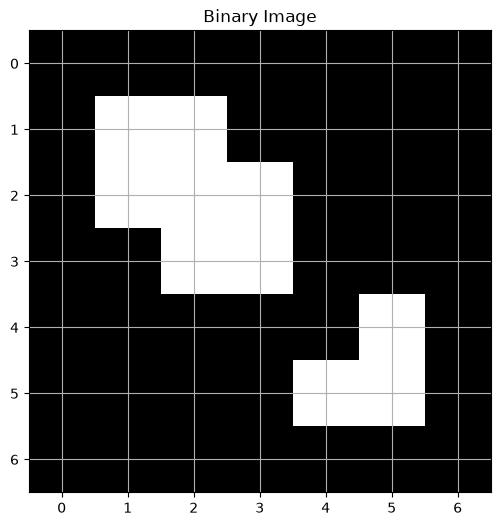

In [2]:
binary_image = np.array([
    [0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 0, 0, 0, 0],
    [0, 1, 1, 1, 0, 0, 0],
    [0, 0, 1, 1, 0, 0, 0],
    [0, 0, 0, 0, 0, 1, 0],
    [0, 0, 0, 0, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0]
])

plt.figure(figsize=(6, 6))
plt.imshow(binary_image, cmap="gray")
plt.title("Binary Image")
plt.xticks(range(binary_image.shape[1]))
plt.yticks(range(binary_image.shape[0]))
plt.grid()
plt.show()

In [3]:
# Select a foreground pixel
r, c = 2, 2
four_directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
eight_directions = four_directions + [(-1, -1), (-1, 1), (1, -1), (1, 1)]

four_neighbors = []
eight_neighbors = []

for dr, dc in four_directions:
    nr, nc = r + dr, c + dc
    if 0 <= nr < binary_image.shape[0] and 0 <= nc < binary_image.shape[1]:
        if binary_image[nr, nc] == 1:
            four_neighbors.append((nr, nc))

for dr, dc in eight_directions:
    nr, nc = r + dr, c + dc
    if 0 <= nr < binary_image.shape[0] and 0 <= nc < binary_image.shape[1]:
        if binary_image[nr, nc] == 1:
            eight_neighbors.append((nr, nc))

print("Selected pixel:", (r, c))
print("4-neighbours:", four_neighbors)
print("8-neighbours:", eight_neighbors)

Selected pixel: (2, 2)
4-neighbours: [(1, 2), (3, 2), (2, 1), (2, 3)]
8-neighbours: [(1, 2), (3, 2), (2, 1), (2, 3), (1, 1), (3, 3)]


In [4]:
# m-connectivity
m_neighbors = four_neighbors.copy()
diagonal_directions = [(-1, -1), (-1, 1), (1, -1), (1, 1)]

for dr, dc in diagonal_directions:
    nr, nc = r + dr, c + dc

    if 0 <= nr < binary_image.shape[0] and 0 <= nc < binary_image.shape[1]:
        if binary_image[nr, nc] == 1:
            common_four = [
                (r, nc), (nr, c)
            ]
            common_values = []
            for ar, ac in common_four:
                if 0 <= ar < binary_image.shape[0] and 0 <= ac < binary_image.shape[1]:
                    common_values.append(binary_image[ar, ac])

            if 1 not in common_values:
                m_neighbors.append((nr, nc))

print("m-neighbours:", m_neighbors)

m-neighbours: [(1, 2), (3, 2), (2, 1), (2, 3)]


In [5]:
p1 = (1, 1)
p2 = (5, 4)

euclidean_distance = sqrt((p2[0] - p1[0])**2 + (p2[1] - p1[1])**2)
city_block_distance = abs(p2[0] - p1[0]) + abs(p2[1] - p1[1])
chessboard_distance = max(abs(p2[0] - p1[0]), abs(p2[1] - p1[1]))

print("Euclidean Distance:", euclidean_distance)
print("City-Block Distance:", city_block_distance)
print("Chessboard Distance:", chessboard_distance)

Euclidean Distance: 5.0
City-Block Distance: 7
Chessboard Distance: 4
